# VinText — Tiền xử lý và cắt ảnh văn bản (Word Cropping)

## Mục tiêu

Chuyển ảnh cảnh tự nhiên của bộ dữ liệu **VinText** cùng các annotation dạng tứ giác (quadrilateral) thành các **ảnh chứa từng vùng văn bản** phục vụ bài toán Scene Text Recognition của Vi-DFD.

## Quy trình xử lý

1. **Khởi tạo:** Xác định đường dẫn dataset, thư mục đầu ra và tỷ lệ lề `10%`.
2. **Đọc dữ liệu:** Ghép từng ảnh `imXXXX.jpg` với annotation `gt_ID.txt`; đọc tọa độ bốn đỉnh và transcript.
3. **Lọc và chuẩn hóa nhãn:** Bỏ vùng `###`, nhãn rỗng; chuẩn hóa Unicode **NFC** để thống nhất cách biểu diễn ký tự tiếng Việt có dấu.
4. **Perspective cropping:** Mở rộng tứ giác theo chiều cao để giữ thêm vùng dấu tiếng Việt, sau đó hiệu chỉnh phối cảnh và cắt ảnh.
5. **Lưu kết quả:** Ghi từng word crop thành PNG, lưu thông tin tương ứng trong `metadata.csv` và lỗi trong `crop_issues.csv`.
6. **Kiểm tra trực quan:** Hiển thị ngẫu nhiên một số ảnh crop cùng transcript để kiểm tra chất lượng.

**Dữ liệu đầu vào:** `dataset/{train_images,test_image,unseen_test_images,labels}`.  
**Đầu ra mặc định:** `processed/vintext_notebook/`.


In [1]:
from pathlib import Path
import csv
import math
import unicodedata
from collections import Counter

import cv2
import numpy as np
from PIL import Image
from IPython.display import display

# Tìm repo root dù notebook nằm trong notesbook/ hay notebooks/
ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục data/ của vi-dfd")
    ROOT = ROOT.parent

DATASET = ROOT.parent / "dataset"
OUTPUT = ROOT.parent / "processed" / "vintext_notebook"  # đổi thành vintext nếu muốn ghi đè
MARGIN = 0.10
SPLITS = {"train": "train_images", "test": "test_image", "unseen_test": "unseen_test_images"}

assert (DATASET / "labels").is_dir(), f"Missing labels: {DATASET}"
for folder in SPLITS.values():
    assert (DATASET / folder).is_dir(), f"Missing images: {DATASET / folder}"
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Dataset:", DATASET)
print("Output:", OUTPUT)

Dataset: D:\BTL_DL\dataset
Output: D:\BTL_DL\processed\vintext_notebook


## Đọc ảnh, phân tích annotation và hiệu chỉnh phối cảnh

Cell này định nghĩa các hàm xử lý cốt lõi:

- **`load_image()` / `save_png()`:** Đọc ảnh JPG và lưu ảnh crop PNG.
- **`parse_annotation()`:** Tách 8 giá trị tọa độ thành bốn điểm của tứ giác và lấy transcript. **Chuẩn hóa NFC được thực hiện tại đây** chuyển các ký tự có nhiều cách biểu diễn Unicode về một dạng thống nhất.
- **`crop_quad()`:** Ước lượng kích thước vùng chữ từ các cạnh tứ giác, mở rộng vùng theo hướng trên/dưới với `margin=0.10`, sau đó dùng Perspective Transform để đưa vùng chữ về ảnh chữ nhật.



In [2]:
def load_image(path):
    raw = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(raw, cv2.IMREAD_COLOR)


def save_png(path, image):
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, encoded = cv2.imencode(".png", image)
    if not ok:
        raise ValueError("PNG encoding failed")
    encoded.tofile(str(path))


def parse_annotation(line):
    parts = line.rstrip("\r\n").split(",", maxsplit=8)
    if len(parts) != 9:
        raise ValueError("Expected 8 coordinates + transcript")
    coords = np.array([float(x.strip()) for x in parts[:8]], dtype=np.float32)
    if not np.isfinite(coords).all():
        raise ValueError("Non-finite coordinates")
    label = unicodedata.normalize("NFC", parts[8].strip())
    return coords.reshape(4, 2), label


def crop_quad(image, quad, margin=0.10):
    # VinText thường lưu các điểm theo thứ tự TL, TR, BR, BL.
    tl, tr, br, bl = quad.astype(np.float32)
    top = np.linalg.norm(tr - tl)
    bottom = np.linalg.norm(br - bl)
    left = np.linalg.norm(bl - tl)
    right = np.linalg.norm(br - tr)
    width = max(1, int(math.ceil(max(top, bottom))))
    height = max(1, int(math.ceil(max(left, right))))
    area = abs(float(cv2.contourArea(quad)))
    if area <= 1 or width < 2 or height < 2:
        raise ValueError("Degenerate quadrilateral")

    # Mở rộng 10% về phía trên và dưới trong hệ tọa độ ảnh gốc.
    left_vector = bl - tl
    right_vector = br - tr
    expanded = np.float32([
        tl - margin * left_vector,
        tr - margin * right_vector,
        br + margin * right_vector,
        bl + margin * left_vector,
    ])
    out_height = max(2, int(math.ceil(height * (1 + 2 * margin))))
    destination = np.float32([
        [0, 0], [width - 1, 0],
        [width - 1, out_height - 1], [0, out_height - 1],
    ])
    matrix = cv2.getPerspectiveTransform(expanded, destination)
    crop = cv2.warpPerspective(
        image, matrix, (width, out_height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REPLICATE,
    )
    return crop, width, height

## Chạy cropping trên toàn bộ VinText

Cell này sử dụng các hàm ở phần 1 để xử lý lần lượt ba tập ảnh **train (1.200 ảnh), test (300 ảnh) và unseen test (500 ảnh)**:

1. Tìm annotation tương ứng cho từng ảnh và đọc các dòng nhãn.
2. Bỏ qua transcript `###` và transcript rỗng; các transcript hợp lệ đã được chuẩn hóa NFC trong `parse_annotation()`.
3. Cắt từng tứ giác thành word crop và lưu PNG vào `crops/<split>/`.
4. Ghi `metadata.csv` gồm split, ảnh gốc, vị trí annotation, đường dẫn crop, transcript và kích thước vùng chữ.
5. Ghi `crop_issues.csv` để theo dõi các trường hợp đọc ảnh, annotation hoặc crop bị lỗi; in tổng kết `saved / ignored / empty / failed`.

OUTPUT sẽ tạo hoặc ghi lại file trong `processed/vintext_notebook/`


In [3]:
records = []
issues = []
counts = Counter()

for split, folder in SPLITS.items():
    image_files = sorted((DATASET / folder).glob("*.jpg"))
    print(f"[{split}] Processing {len(image_files)} images")
    for image_path in image_files:
        image_id = int(image_path.stem.removeprefix("im"))
        annotation_path = DATASET / "labels" / f"gt_{image_id}.txt"
        if not annotation_path.exists():
            counts["failed"] += 1
            issues.append([split, image_path.name, 0, "Missing annotation"])
            continue
        image = load_image(image_path)
        if image is None:
            counts["failed"] += 1
            issues.append([split, image_path.name, 0, "Cannot decode image"])
            continue

        for line_no, line in enumerate(annotation_path.read_text(encoding="utf-8-sig").splitlines(), 1):
            try:
                quad, transcript = parse_annotation(line)
                if transcript == "###":
                    counts["ignored"] += 1
                    continue
                if not transcript:
                    counts["empty"] += 1
                    continue
                crop, original_width, original_height = crop_quad(image, quad, MARGIN)
                relative_path = Path("crops") / split / f"{image_path.stem}_line{line_no:04d}.png"
                save_png(OUTPUT / relative_path, crop)
                records.append({
                    "split": split,
                    "image_id": image_id,
                    "source_image": str(Path(folder) / image_path.name),
                    "annotation_file": annotation_path.name,
                    "line_number": line_no,
                    "crop_path": relative_path.as_posix(),
                    "transcript": transcript,
                    "crop_width": crop.shape[1],
                    "crop_height": crop.shape[0],
                    "original_word_height": original_height,
                    "original_word_width": original_width,
                })
                counts["saved"] += 1
            except Exception as exc:
                counts["failed"] += 1
                issues.append([split, image_path.name, line_no, str(exc)])
    print(f"[{split}] Finished")

columns = ["split", "image_id", "source_image", "annotation_file", "line_number",
           "crop_path", "transcript", "crop_width", "crop_height",
           "original_word_height", "original_word_width"]
with (OUTPUT / "metadata.csv").open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=columns)
    writer.writeheader()
    writer.writerows(records)
with (OUTPUT / "crop_issues.csv").open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.writer(f)
    writer.writerow(["split", "source_image", "line_number", "reason"])
    writer.writerows(issues)

print("\nVINTEXT CROPPING SUMMARY")
for key in ["saved", "ignored", "empty", "failed"]:
    print(f"{key:8}: {counts[key]}")
print("Output:", OUTPUT)
print("Metadata:", OUTPUT / "metadata.csv")

[train] Processing 1200 images
[train] Finished
[test] Processing 300 images
[test] Finished
[unseen_test] Processing 500 images
[unseen_test] Finished

VINTEXT CROPPING SUMMARY
saved   : 43045
ignored : 12984
empty   : 55
failed  : 0
Output: D:\BTL_DL\processed\vintext_notebook
Metadata: D:\BTL_DL\processed\vintext_notebook\metadata.csv


## 3. Kiểm tra trực quan kết quả cropping

Cell này chọn ngẫu nhiên **8 word crops** từ các mẫu vừa xử lý và hiển thị trực tiếp trong notebook cùng **split, transcript và tên file**.

Mục đích kiểm tra:

- Chữ trong ảnh crop có khớp với transcript không.
- Dấu tiếng Việt ở mép trên/dưới có được giữ đầy đủ không.
- Có ký tự bị cắt, ảnh bị méo hoặc chứa quá nhiều nền không.



unseen_test | LEADERS | crops/unseen_test/im1952_line0008.png


train | IN | crops/train/im0324_line0009.png


train | 29/1 | crops/train/im0073_line0049.png


train | DÂN | crops/train/im0836_line0006.png


train | 18.000.000Đ | crops/train/im0743_line0025.png


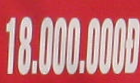

train | Giả | crops/train/im0681_line0012.png


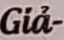

train | 2015! | crops/train/im0407_line0021.png


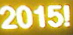

train | HÙNG | crops/train/im0300_line0007.png


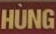

In [4]:
import random
random.seed(42)
for record in random.sample(records, min(8, len(records))):
    print(f"{record['split']} | {record['transcript']} | {record['crop_path']}")
    display(Image.open(OUTPUT / record["crop_path"]))

## 4. Kết quả và bước tiếp theo

Sau khi chạy thành công, thư mục đầu ra gồm:

```text
processed/vintext_notebook/
├── crops/
│   ├── train/
│   ├── test/
│   └── unseen_test/
├── metadata.csv
└── crop_issues.csv
```

- **`crops/`**: Ảnh văn bản đã được hiệu chỉnh phối cảnh.
- **`metadata.csv`**: Liên kết ảnh crop với nhãn Unicode NFC và thông tin ảnh gốc.
- **`crop_issues.csv`**: Danh sách lỗi để kiểm tra và xử lý.

**Tiếp theo:** Dùng metadata, ảnh crop và annotation gốc để thực hiện EDA; kiểm tra chất lượng dữ liệu, sau đó chia train/validation theo **ảnh gốc** nhằm tránh rò rỉ dữ liệu. Chỉ đóng gói LMDB sau khi hoàn thành kiểm tra và cố định các split.
